In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score
import math

In [2]:
#Function to fit models to data
def fit_models(x, y, models):
    #Values to be fitted
    x = np.asarray(x)
    y = np.asarray(y)

    #Expanded x values for finer predictions for plotting
    x_points = np.linspace(min(x), max(x)*1.5, 1000)

    #Initiate data storage
    results = {}
    #Actual values to compare fitted curves with
    fits = pd.DataFrame({ 
            "model": ["actual"] * len(x),
            "x_pred_points": x,
            "y_pred_points": y,
            })
    
    for name, func in models.items():
        try:
            #Fit model and predict
            params, _ = curve_fit(func, x, y, maxfev=10000)

            y_pred = func(x, *params)
            y_pred_points = func(x_points, *params)

            #Metrics
            errors = y_pred - y
            r2 = r2_score(y, y_pred)
            rss = np.sum((y - y_pred) ** 2)
            n = len(y)
            rmse = np.sqrt(rss/n)
            k = len(params)
            aic = n * np.log(rss / n) + 2 * k

            results[name] = {
                "params": params,
                "r2": r2,
                "rmse": rmse,
                "aic": aic,
                "actuals": y,
                "preds": y_pred,
                "errors": errors,
                "mae": np.mean(np.abs(errors)),
                "abs_errors": np.abs(errors),
            }

            fit_df = pd.DataFrame({
                "model": name,
                "x_pred_points": x_points,
                "y_pred_points": y_pred_points,
            })
            fits = pd.concat([fits, fit_df], ignore_index=True)
        
        except FloatingPointError as e:
            print(f"\nModel '{name}' failed with params: {params if 'params' in locals() else None}")

    return results, fits

In [3]:
#Load curve with pShh x100 guide titration
titration = pd.read_table("pShhx100_titration_data.txt")
titration = titration[titration["dilution"]!="NT"].copy()
titration.head()

,rep,dilution,amount,median,mean,stdev,background,N,median_minus_bg,CV,log2_fc_vs_bg
0,1,1,450.000,38851.25,44457.721793,28819.175255,107.88,2800,38743.37,0.648238,8.492390
1,1,10,45.000,21845.25,27604.553955,25030.174019,107.88,2956,21737.37,0.906741,7.661748
2,1,100,4.500,224.13,1519.711690,4740.010786,107.88,2657,116.25,3.119020,1.054908
3,1,1000,0.450,109.74,134.507971,118.721637,107.88,2923,1.86,0.882636,0.024662
4,1,10000,0.045,97.65,117.314220,80.164411,107.88,2730,-10.23,0.683331,-0.143735


In [4]:
#Define various sigmoidal models
def hill(x, Vmax, K, n):
    return Vmax * (x**n) / (K**n + x**n)
def logistic(x, L, k, x0):
    return L / (1 + np.exp(-k * (x - x0)))
def logistic_4p(x, A, B, k, x0):
    return A + (B - A) / (1 + np.exp(-k * (x - x0)))
def logistic_5p(x, A, B, k, x0, v):
    return A + (B - A) / (1 + np.exp(-k * (x - x0)))**(v)
def gompertz(x, a, b, c):
    return a * np.exp(-b * np.exp(-c * x))
def weibull_sigmoid(x, L, k, lam):
    return L * (1 - np.exp(-(x / lam)**k))
def tanh(x, a, b, c, d):
    return a * np.tanh(b * (x - c)) + d

models = {
    "hill": hill,
    "logistic": logistic,
    "logistic_4p": logistic_4p,
    "logistic_5p": logistic_5p,
    "gompertz": gompertz,
    "weibull": weibull_sigmoid,
    "tanh": tanh,
}

In [5]:
#Fit models to data
x = titration["amount"]
y = titration["log2_fc_vs_bg"]

results, fits = fit_models(x, y, models)

/local/55263823.1.igmm_long/ipykernel_1274478/149802516.py:5: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp(-k * (x - x0)))
/local/55263823.1.igmm_long/ipykernel_1274478/149802516.py:7: RuntimeWarning: overflow encountered in exp
  return A + (B - A) / (1 + np.exp(-k * (x - x0)))
/local/55263823.1.igmm_long/ipykernel_1274478/149802516.py:9: RuntimeWarning: overflow encountered in exp
  return A + (B - A) / (1 + np.exp(-k * (x - x0)))**(v)
/local/55263823.1.igmm_long/ipykernel_1274478/149802516.py:9: RuntimeWarning: overflow encountered in power
  return A + (B - A) / (1 + np.exp(-k * (x - x0)))**(v)
/local/55263823.1.igmm_long/ipykernel_1274478/149802516.py:11: RuntimeWarning: overflow encountered in exp
  return a * np.exp(-b * np.exp(-c * x))


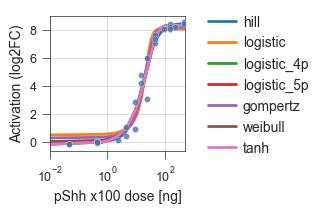

In [6]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1.75,1.75), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})
g = sns.lineplot(data=fits[fits.model!="actual"], x="x_pred_points", y="y_pred_points", hue="model", palette="tab10", 
                linewidth=2, legend=True)
sns.scatterplot(fits[fits.model=="actual"],  x="x_pred_points", y="y_pred_points", ax=g, legend=False, s=20, linewidth=0.25, alpha=0.8, zorder=10)
g.set(xscale="log", xlim=[0.01,500])
g.grid(True, linewidth=0.5)
sns.move_legend(obj=g, loc="upper right", frameon=False, bbox_to_anchor=(2,1.1), title="", handletextpad=0.5, fontsize=10)
g.set_ylabel("Activation (log2FC)", fontsize=10)
g.set_xlabel("pShh x100 dose [ng]", fontsize=10)
g.tick_params(labelsize=9)

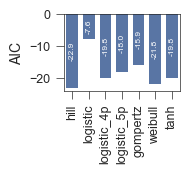

In [7]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1.5,1), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})
df=pd.DataFrame(results).T[["r2","rmse","aic"]].reset_index()
g = sns.barplot(data=df, x="index", y="aic", linewidth=0, width=0.7)
g.set(xlabel="")
plt.xticks(rotation=90)
for container in g.containers:
    g.bar_label(
        container,
        fmt="%.1f", 
        label_type="center",
        fontsize=6,
        rotation=90,
        color="white"
    )
g.set_ylabel("AIC", fontsize=10)
g.tick_params(labelsize=9)

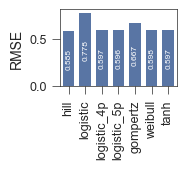

In [8]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1.5,1), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})
df=pd.DataFrame(results).T[["r2","rmse","aic"]].reset_index()
g = sns.barplot(data=df, x="index", y="rmse", linewidth=0, width=0.7)
g.set(xlabel="")
plt.xticks(rotation=90)
for container in g.containers:
    g.bar_label(
        container,
        fmt="%.3f",
        label_type="center", 
        fontsize=6,
        rotation=90,
        color="white"  
    )
g.set_ylabel("RMSE", fontsize=10)
g.tick_params(labelsize=9)

In [9]:
comb = pd.read_table("SingleDualActivation_data.txt")
comb = comb[comb["guide"]!="NT"]
comb.sort_values("rep").head(5)

,rep,guide,treatment,median,mean,stdev,background,N,median_minus_bg,CV,log2_fc_vs_bg
1,1,SBE2,UNT_Shh::mGL,355.105,859.455156,1420.113306,94.01,3790,261.095,1.652341,1.917360
2,1,SBE6,UNT_Shh::mGL,238.580,407.753436,533.026314,94.01,3315,144.570,1.307227,1.343587
3,1,SBE6+SBE2,UNT_Shh::mGL,1119.430,2141.715009,2814.609207,94.01,4989,1025.420,1.314185,3.573806
9,2,SBE6,dTAG_dTAG-NIPBL,244.770,447.522139,566.911505,82.82,2412,161.950,1.266779,1.563376
7,2,SBE2,DMSO_dTAG-NIPBL,515.780,1052.218039,1503.954128,73.80,1540,441.980,1.429318,2.805063


In [10]:
def safe_log2(x):
    return np.log2(x) if x > 0 else np.nan

#Function to predict combinations based on inverse functions
def predict_combinations(
    df,
    guide_col="guide",
    value_col="median",
    bg_col="background",
    group_cols=("rep", "treatment"),
    func=None,
    invert_func=None,
    params=None,
    space="linear",
    func_name="",
    ):
    #Get all combinations
    guides = df.loc[df[guide_col].str.contains("+", regex=False), guide_col].unique()
    combo_map = {g: tuple(g.split("+")) for g in guides}

    #Checks
    if func is None or invert_func is None:
        raise ValueError("Provide functions")
    if params is None:
        warnings.warn("No model parameters provided")
        params = ()
    if space not in ("linear", "log2"):
        raise ValueError("space must be 'linear' or 'log2'")

    #Initiate data storage
    results = []

    #For each group
    group_cols = list(group_cols)
    for group_key, subdf in df.groupby(group_cols):
        #Check there is only one background per groupby
        unique_bg = subdf[bg_col].unique()
        if len(unique_bg) != 1:
            raise ValueError(f"Multiple backgrounds in group {group_key}: {unique_bg}")
        bg = unique_bg[0]
        if bg <= 0:
            raise ValueError(f"Background must be >0 in group {group_key}")

        #Get values
        val_lookup = dict(zip(subdf[guide_col], subdf[value_col]))

        for combo_name, parts in combo_map.items():
            #If not combo in this groupby, skip
            if not all(p in val_lookup for p in parts) or not combo_name in val_lookup:
                continue
            
            y1, y2 = [val_lookup[p]/bg for p in parts]  

            if space == "log2":
                y1 = safe_log2(y1)
                y2 = safe_log2(y2)
                
            y_combo = val_lookup[combo_name]
            #Convert actual fold-change to log2 for comparisons
            actual = safe_log2(y_combo / bg)

            #Make prediction
            pred = np.nan
            #Special case for additive when baseline has to be subtracted (y=1 if no effect, i.e. y=bg),
            if func_name.lower() == "additive" and space=="linear":
                warnings.warn("Treating additive model in linear space according to pred=fc1+fc2-1")
                pred = y1 + y2 - 1
            #Get the inverted x values and predict f(x1+x2) with forward function
            else:
                try:
                    x1 = invert_func(y1, *params)
                    x2 = invert_func(y2, *params)
                    pred = func(x1+x2, *params)
                except Exception as e:
                    warnings.warn(f"Cannot predict {combo_name} with {func_name} for {group_key}: {e}")
            
            #Convert linear predictions to log2 for comparisons
            if space == "linear":
                pred_log2 = safe_log2(pred)
            else:
                pred_log2 = pred

            #Store values
            row = {
                **dict(zip(group_cols, group_key if isinstance(group_key, tuple) else (group_key,))),
                "combo": combo_name,
                "predicted_log2": pred_log2,
                "actual_log2": actual,
                "function": func_name,
            }

            #Error metrics
            if not np.isnan(actual) and not np.isnan(pred_log2):
                error = pred_log2 - actual
                rel_error = (2**pred_log2 - 2**actual) / (2**actual)
                row["error"] = error
                row["rel_error"] = rel_error
                row["abs_error"] = abs(error)

            results.append(row)

    return pd.DataFrame(results)

In [11]:
#Predict the combined responses using the additive and multiplicative models
def forward_add(x):
        return x

pred_add = predict_combinations(
    comb,
    value_col="median",
    bg_col="background",
    func=forward_add,
    invert_func=forward_add,
    func_name="Additive",
    space="linear",
)

pred_mult = predict_combinations(
    comb,
    value_col="median",
    bg_col="background",
    func=forward_add,
    invert_func=forward_add,
    func_name="Multiplicative",
    space="log2",
)

#Predict the combined responses using a capped multiplicative model at the highest observed log2FC
#values of the guide with the highest mean
mean_max = np.max(comb.groupby("guide").mean(numeric_only=True)["log2_fc_vs_bg"])
def forward_add_max(x, xmax=mean_max):
    if x >= xmax:
        return xmax
    else:
        return x

pred_mult_cap = predict_combinations(
    comb,
    value_col="median",
    bg_col="background",
    func=forward_add_max,
    invert_func=forward_add,
    func_name="Capped mult.",
    space="log2",
)

/local/55263823.1.igmm_long/ipykernel_1274478/1029988022.py:25: UserWarning: No model parameters provided
  warnings.warn("No model parameters provided")
/local/55263823.1.igmm_long/ipykernel_1274478/1029988022.py:66: UserWarning: Treating additive model in linear space according to pred=fc1+fc2-1
  warnings.warn("Treating additive model in linear space according to pred=fc1+fc2-1")
/local/55263823.1.igmm_long/ipykernel_1274478/1029988022.py:25: UserWarning: No model parameters provided
  warnings.warn("No model parameters provided")
/local/55263823.1.igmm_long/ipykernel_1274478/1029988022.py:25: UserWarning: No model parameters provided
  warnings.warn("No model parameters provided")


In [12]:
#Set x boundaries
x_bounds=(0,500)

#Define inverse functions with caps at set x boundaries 
#(i.e. if observed value is higher/lower than can be found in model prediction, give highest/lowest x)

#Define analytical inverse Hill function with clipping at x boundaries
def inverse_hill(y, Vmax, K, n, x_bounds=x_bounds, clip=True, eps=1e-6):
    lo, hi = x_bounds
    y_sat = Vmax * (1 - eps)
    if y <= 0:
        return lo if clip else ValueError("y <= 0")
    if y >= y_sat:
        return hi if clip else ValueError("y >= Vmax")
    else:
        return K * (y / (Vmax - y))**(1/n)
        
#Define analytical inverse 4-parameter logistic function with clipping at x boundaries
def logistic_4p_inv(y, A, B, k, x0, x_bounds=x_bounds, clip=True):
    lo, hi = x_bounds
    if y <= A:
        return lo if clip else ValueError("y <= 0")
    if y >= B:
        return hi if clip else ValueError("y >= B")
    return x0 - (1/k) * np.log((B - A)/(y - A) - 1)

#Define analytical inverse Weibull sigmoid function with clipping at x boundaries
def inverse_weibull(y, L, k, lam, x_bounds=x_bounds, clip=True):
    lo, hi = x_bounds
    if y <= 0:
        return lo if clip else ValueError("y <= 0")
    if y >= L:
        return hi if clip else ValueError("y >= L")
    return lam * (-np.log(1 - y / L))**(1 / k)

#Define analytical inverse tanh function with clipping at x boundaries
def inverse_tanh(y, a, b, c, d, x_bounds=x_bounds, clip=True):
    lo, hi = x_bounds
    y_sat_hi = (d + a)
    y_sat_lo = (d - a)
    if y <= y_sat_lo:
        return lo if clip else ValueError("y <= d - a")
    if y >= y_sat_hi:
        return hi if clip else ValueError("y >= d + a")
    z = (y - d) / a
    return c + (1 / b) * math.atanh(z)

In [13]:
#Predict the combined responses using the fit Hill and inverse Hill
pred_hill = predict_combinations(
    comb,
    value_col="median",
    bg_col="background",
    func=hill,
    invert_func=inverse_hill,
    params=results["hill"]["params"],
    func_name="Hill",
    space="log2",
)

#Predict the combined responses using the fit 4-parameter logistic and its inverse
pred_log4p = predict_combinations(
    comb,
    value_col="median",
    bg_col="background",
    func=logistic_4p,
    invert_func=logistic_4p_inv,
    params=results["logistic_4p"]["params"],
    func_name="log4p",
    space="log2",
)

#Predict the combined responses using the fit tanh and inverse tanh
pred_tanh = predict_combinations(
    comb,
    value_col="median",
    bg_col="background",
    func=tanh,
    invert_func=inverse_tanh,
    params=results["tanh"]["params"],
    func_name="tanh",
    space="log2",
)

#Predict the combined responses using the fit weibull and inverse weibull
pred_weib = predict_combinations(
    comb,
    value_col="median",
    bg_col="background",
    func=weibull_sigmoid,
    invert_func=inverse_weibull,
    params=results["weibull"]["params"],
    func_name="weibull",
    space="log2",
)

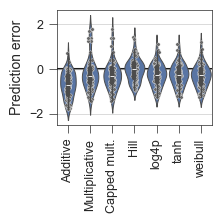

In [14]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(2,1.5), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})
pred_all = pd.concat([pred_add, pred_mult, pred_mult_cap, pred_hill, pred_log4p, pred_tanh, pred_weib]).reset_index(drop=True)
pred_all["treatment"] = np.where(pred_all["treatment"].isin(["UNT_Shh::mGL", "DMSO_dTAG-NIPBL", "UNT_dTAG-NIPBL", "DMSO_WAPL-dTAG"]), "UNT", pred_all["treatment"])
func_order = pred_all.function.unique()
g = sns.violinplot(data=pred_all, y="error", x="function", width=0.9, linewidth=0.7, order = func_order)
sns.stripplot(data=pred_all, y="error", x="function", ax=g, linewidth=0.25, 
              edgecolor="white", color="dimgrey", s=2.5, zorder=1, order = func_order)
plt.xticks(rotation=90)
g.set(xlabel="")
g.grid(True, axis="y", linewidth=0.5)
plt.axhline(0, color="k",zorder=0)
g.set_ylabel("Prediction error", fontsize=10)
g.tick_params(labelsize=9)

In [15]:
#Function to calculate goodness-of-fit of different models
def model_criteria(actuals, predicted, k):
    #Mask NaNs
    mask = ~np.isnan(actuals) & ~np.isnan(predicted)
    y_true = np.array(actuals)[mask]
    y_pred = np.array(predicted)[mask]
    
    n = len(y_true)
    if n == 0:
        return pd.DataFrame({"RMSE": [np.nan], "MAE": [np.nan], "R2": [np.nan], "AIC": [np.nan]})

    errors = y_pred - y_true
    r2 = r2_score(y_true, y_pred)
    mae = np.mean(np.abs(errors))
    rss = np.sum((y_true - y_pred) ** 2)
    rmse = np.sqrt(rss/n)
    aic = n * np.log(rss / n) + 2 * k
        
    return pd.Series({"RMSE": rmse, "MAE": mae, "R2": r2, "AIC": aic})

#Function for groupby
def model_criteria_group(group, k):
    actuals = group["actual_log2"].to_numpy()
    predicted = group["predicted_log2"].to_numpy()
    return model_criteria(actuals, predicted, k)

In [16]:
k_map = {"Additive": 0, "Multiplicative": 0, "Capped mult.": 0, "log4p": 4, "tanh": 4, "Hill": 3, "weibull": 3}

#Calculate metrics
metrics = pred_all.groupby("function").apply(
    lambda x: model_criteria_group(x, k=k_map.get(x.name, np.nan))
).reset_index()

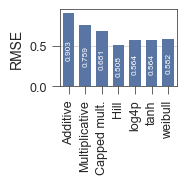

In [17]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1.5,1), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})
g = sns.barplot(data=metrics, x="function", y="RMSE", linewidth=0, width=0.7, order= func_order)
g.set(xlabel="")
plt.xticks(rotation=90)
g.grid(True, axis="y", linewidth=0.5)
for container in g.containers:
    g.bar_label(
        container,
        fmt="%.3f",
        label_type="center",
        fontsize=6,
        rotation=90,
        color="white"
    )
g.set_ylabel("RMSE", fontsize=10)
g.tick_params(labelsize=9)

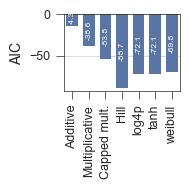

In [18]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1.5,1), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})
g = sns.barplot(data=metrics, x="function", y="AIC", linewidth=0, width=0.7, order= func_order)
g.set(xlabel="")
plt.xticks(rotation=90)
g.grid(True, axis="y", linewidth=0.5)
for container in g.containers:
    g.bar_label(
        container,
        fmt="%.1f",
        label_type="center", 
        fontsize=6,
        rotation=90,
        color="white"
    )
g.set_ylabel("AIC", fontsize=10)
g.tick_params(labelsize=9)

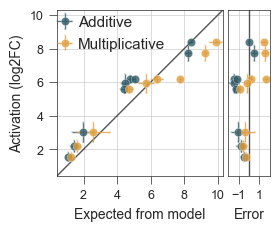

In [19]:
palette=["#335c67", "#e09f3e", "#9e2a2b", "#3c627c","#305f51", "#7f6b9e"]

sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1.5,3), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})

#All unperturbed conditions
df = pred_all[pred_all["treatment"].isin(["UNT"])].copy()
df_err = df.groupby(["combo", "function"]).aggregate("std", numeric_only=True).reset_index()
df_mean = df.groupby(["combo", "function"]).aggregate("mean", numeric_only=True).reset_index()

#Plot parameters
ratio = 4
fig, (ax1, ax2) = plt.subplots(ncols=2, sharey=False, figsize=(2.75,2.75), gridspec_kw={'width_ratios': [ratio, 1], 'wspace': 0.05})

#Additive
ax1.errorbar(
    x=df_mean.loc[df_mean["function"]=="Additive", "predicted_log2"], 
    y=df_mean.loc[df_mean["function"]=="Additive", "actual_log2"],
    xerr=df_err.loc[df_err["function"]=="Additive", "predicted_log2"], 
    yerr=df_err.loc[df_err["function"]=="Additive", "actual_log2"],
    fmt="o", color=palette[0], alpha=0.8, label="Additive",
    markeredgecolor="white", elinewidth=1, capsize=1, 
    markersize=6, markeredgewidth=0.25,
)

#Multiplicative
ax1.errorbar(
    x=df_mean.loc[df_mean["function"]=="Multiplicative", "predicted_log2"], 
    y=df_mean.loc[df_mean["function"]=="Additive", "actual_log2"],
    xerr=df_err.loc[df_err["function"]=="Multiplicative", "predicted_log2"], 
    yerr=df_err.loc[df_err["function"]=="Additive", "actual_log2"],
    fmt="o", color=palette[1], alpha=0.8, label="Multiplicative",
    markeredgecolor="white", elinewidth=1, capsize=1, 
    markersize=6, markeredgewidth=0.25,
)

ax1.set_box_aspect(1)

#Additive errors
ax2.errorbar(
    x=df_mean.loc[df_mean["function"]=="Additive", "error"], 
    y=df_mean.loc[df_mean["function"]=="Additive", "actual_log2"],
    xerr=df_err.loc[df_err["function"]=="Additive", "error"], 
    yerr=df_err.loc[df_err["function"]=="Additive", "actual_log2"],
    fmt="o", color=palette[0], alpha=0.8, label="Additive",
    markeredgecolor="white", elinewidth=1, capsize=1, 
    markersize=6, markeredgewidth=0.25,
)

#Multiplicative erros
ax2.errorbar(
    x=df_mean.loc[df_mean["function"]=="Multiplicative", "error"], 
    y=df_mean.loc[df_mean["function"]=="Additive", "actual_log2"],
    xerr=df_err.loc[df_err["function"]=="Multiplicative", "error"], 
    yerr=df_err.loc[df_err["function"]=="Additive", "actual_log2"],
    fmt="o", color=palette[1], alpha=0.8, label="Multiplicative",
    markeredgecolor="white", elinewidth=1, capsize=1, 
    markersize=6, markeredgewidth=0.25,
)

ax2.set_box_aspect(ratio)

#axis and legend settings
ax1.set_ylabel("Measured")
ax1.set_xlabel("Expected")
ax1.legend(title="", loc="upper left", frameon=False, bbox_to_anchor=(-0.127,1.05), handletextpad=-0.1,)
ax1.set_xlim([0.4, 10.3])
ax1.set_ylim([0.4, 10.3])
ax2.set_ylim([0.4, 10.3])
ax2.axvline(0, color="k", alpha=0.75, linewidth=1)
ax1.set_yticks([2, 4, 6, 8, 10])
ax1.set_xticks([2, 4, 6, 8, 10])
ax2.set_xticks([-1, 1])
ax2.set_xlim([-2,2])
ax1.set_ylabel("")
ax1.set_ylabel("Activation (log2FC)", fontsize=10)
ax1.set_xlabel("Expected from model", fontsize=10)
ax2.set_xlabel("Error", fontsize=10)
ax2.tick_params(axis='y', which='both', left=False, labelleft=False)
ax1.grid(True, linewidth=0.5)
ax2.grid(True, linewidth=0.5)

#Line at y=x
lims = [
    np.min([ax1.get_xlim(), ax1.get_ylim()]),
    np.max([ax1.get_xlim(), ax1.get_ylim()]),
]
ax1.plot(lims, lims, "k-", alpha=0.75, zorder=1, linewidth=1)

ax1.tick_params(labelsize=9)
ax2.tick_params(labelsize=9)

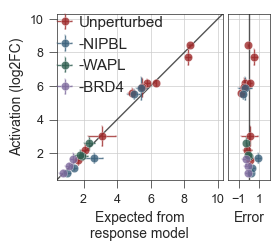

In [20]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1.5,3), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})

#All conditions
df = pred_all
df_err = df.groupby(["combo", "function", "treatment"]).aggregate("std", numeric_only=True).reset_index()
df_mean = df.groupby(["combo", "function", "treatment"]).aggregate("mean", numeric_only=True).reset_index()

df_mean_unt = df_mean[df_mean["treatment"]=="UNT"]
df_err_unt = df_err[df_err["treatment"]=="UNT"]
df_mean_nipbl = df_mean[df_mean["treatment"]=="dTAG_dTAG-NIPBL"]
df_err_nipbl = df_err[df_err["treatment"]=="dTAG_dTAG-NIPBL"]
df_mean_wapl = df_mean[df_mean["treatment"]=="dTAG_WAPL-dTAG"]
df_err_wapl = df_err[df_err["treatment"]=="dTAG_WAPL-dTAG"]
df_mean_brd4 = df_mean[df_mean["treatment"]=="MZ1_WAPL-dTAG"]
df_err_brd4 = df_err[df_err["treatment"]=="MZ1_WAPL-dTAG"]

#Plot parameters
ratio = 4
fig, (ax1, ax2) = plt.subplots(ncols=2, sharey=False, figsize=(2.75,2.75), gridspec_kw={'width_ratios': [ratio, 1], 'wspace': 0.05})

#Response untreated
ax1.errorbar(
    x=df_mean_unt.loc[df_mean_unt["function"]=="Hill", "predicted_log2"], 
    y=df_mean_unt.loc[df_mean_unt["function"]=="Hill", "actual_log2"],
    xerr=df_err_unt.loc[df_err_unt["function"]=="Hill", "predicted_log2"], 
    yerr=df_err_unt.loc[df_err_unt["function"]=="Hill", "actual_log2"],
    fmt="o", color=palette[2], alpha=0.8, label="Unperturbed",
    markeredgecolor="white", elinewidth=1, capsize=1, 
    markersize=6, markeredgewidth=0.25,
)

ax1.set_box_aspect(1)

#NIPBL
ax1.errorbar(
    x=df_mean_nipbl.loc[df_mean_nipbl["function"]=="Hill", "predicted_log2"], 
    y=df_mean_nipbl.loc[df_mean_nipbl["function"]=="Hill", "actual_log2"],
    xerr=df_err_nipbl.loc[df_err_nipbl["function"]=="Hill", "predicted_log2"], 
    yerr=df_err_nipbl.loc[df_err_nipbl["function"]=="Hill", "actual_log2"],
    fmt="o", color=palette[3], alpha=0.8, label="-NIPBL",
    markeredgecolor="white", elinewidth=1, capsize=1, 
    markersize=6, markeredgewidth=0.25,
)

#WAPL
ax1.errorbar(
    x=df_mean_wapl.loc[df_mean_wapl["function"]=="Hill", "predicted_log2"], 
    y=df_mean_wapl.loc[df_mean_wapl["function"]=="Hill", "actual_log2"],
    xerr=df_err_wapl.loc[df_err_wapl["function"]=="Hill", "predicted_log2"], 
    yerr=df_err_wapl.loc[df_err_wapl["function"]=="Hill", "actual_log2"],
    fmt="o", color=palette[4], alpha=0.8, label="-WAPL",
    markeredgecolor="white", elinewidth=1, capsize=1, 
    markersize=6, markeredgewidth=0.25,
)

#MZ1
ax1.errorbar(
    x=df_mean_brd4.loc[df_mean_brd4["function"]=="Hill", "predicted_log2"], 
    y=df_mean_brd4.loc[df_mean_brd4["function"]=="Hill", "actual_log2"],
    xerr=df_err_brd4.loc[df_err_brd4["function"]=="Hill", "predicted_log2"], 
    yerr=df_err_brd4.loc[df_err_brd4["function"]=="Hill", "actual_log2"],
    fmt="o", color=palette[5], alpha=0.8, label="-BRD4",
    markeredgecolor="white", elinewidth=1, capsize=1, 
    markersize=6, markeredgewidth=0.25,
)

#Response errors untreated
ax2.errorbar(
    x=df_mean_unt.loc[df_mean_unt["function"]=="Hill", "error"], 
    y=df_mean_unt.loc[df_mean_unt["function"]=="Hill", "actual_log2"],
    xerr=df_err_unt.loc[df_err_unt["function"]=="Hill", "error"], 
    yerr=df_err_unt.loc[df_err_unt["function"]=="Hill", "actual_log2"],
    fmt="o", color=palette[2], alpha=0.8, 
    markeredgecolor="white", elinewidth=1, capsize=1, 
    markersize=6, markeredgewidth=0.25,
)

#NIPBL errors
ax2.errorbar(
    x=df_mean_nipbl.loc[df_mean_nipbl["function"]=="Hill", "error"], 
    y=df_mean_nipbl.loc[df_mean_nipbl["function"]=="Hill", "actual_log2"],
    xerr=df_err_nipbl.loc[df_err_nipbl["function"]=="Hill", "error"], 
    yerr=df_err_nipbl.loc[df_err_nipbl["function"]=="Hill", "actual_log2"],
    fmt="o", color=palette[3], alpha=0.8, 
    markeredgecolor="white", elinewidth=1, capsize=1, 
    markersize=6, markeredgewidth=0.25,
)

#WAPL errors
ax2.errorbar(
    x=df_mean_wapl.loc[df_mean_wapl["function"]=="Hill", "error"], 
    y=df_mean_wapl.loc[df_mean_wapl["function"]=="Hill", "actual_log2"],
    xerr=df_err_wapl.loc[df_err_wapl["function"]=="Hill", "error"], 
    yerr=df_err_wapl.loc[df_err_wapl["function"]=="Hill", "actual_log2"],
    fmt="o", color=palette[4], alpha=0.8, 
    markeredgecolor="white", elinewidth=1, capsize=1, 
    markersize=6, markeredgewidth=0.25,
)

#MZ1 errors
ax2.errorbar(
    x=df_mean_brd4.loc[df_mean_brd4["function"]=="Hill", "error"], 
    y=df_mean_brd4.loc[df_mean_brd4["function"]=="Hill", "actual_log2"],
    xerr=df_err_brd4.loc[df_err_brd4["function"]=="Hill", "error"], 
    yerr=df_err_brd4.loc[df_err_brd4["function"]=="Hill", "actual_log2"],
    fmt="o", color=palette[5], alpha=0.8, 
    markeredgecolor="white", elinewidth=1, capsize=1, 
    markersize=6, markeredgewidth=0.25,
)


ax2.set_box_aspect(ratio)

#axis and legend settings
ax1.set_ylabel("Measured")
ax1.set_xlabel("Expected")
ax1.legend(title="", loc="upper left", frameon=False, bbox_to_anchor=(-0.127,1.07), handletextpad=-0.1,)
ax1.set_xlim([0.4, 10.3])
ax1.set_ylim([0.4, 10.3])
ax2.set_ylim([0.4, 10.3])
ax2.axvline(0, color="k", alpha=0.75, linewidth=1)
ax1.set_yticks([2, 4, 6, 8, 10])
ax1.set_xticks([2, 4, 6, 8, 10])
ax2.set_xticks([-1, 1])
ax2.set_xlim([-2,2])
ax1.set_ylabel("")
ax1.set_ylabel("Activation (log2FC)", fontsize=10)
ax1.set_xlabel("Expected from\nresponse model", fontsize=10)
ax2.set_xlabel("Error", fontsize=10)
ax2.tick_params(axis='y', which='both', left=False, labelleft=False)
ax1.grid(True, linewidth=0.5)
ax2.grid(True, linewidth=0.5)
ax1.tick_params(labelsize=9)
ax2.tick_params(labelsize=9)
#Line at y=x
lims = [
    np.min([ax1.get_xlim(), ax1.get_ylim()]),
    np.max([ax1.get_xlim(), ax1.get_ylim()]),
]
ax1.plot(lims, lims, "k-", alpha=0.75, zorder=1, linewidth=1)

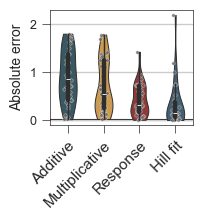

In [21]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1.85,1.5), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})

#All unperturbed predictions
df = pred_all[pred_all["treatment"].isin(["UNT"])].replace("Hill", "Response")
#Fitting error from hill fit
df2 = pd.DataFrame({"function": ["Hill fit"]*len(results["hill"]["preds"]), 
                    "abs_error": np.array(results["hill"]["abs_errors"])})
dfplot = pd.concat([df, df2]).reset_index(drop=True)

order= ["Additive", "Multiplicative", "Response", "Hill fit"]
g = sns.violinplot(data=dfplot, palette=palette[:4], cut=0, hue="function", hue_order=order,
                y="abs_error", x="function", order=order, width=0.5, linewidth=0.7,
                density_norm='width',
                )
sns.stripplot(data=dfplot, 
                y="abs_error", x="function", dodge=False, jitter=0.1, color="dimgrey", zorder=1,
                edgecolor="white", linewidth=0.25, s=2.5, alpha=0.8, ax=g, order=order,
                )
g.set(yscale="linear", xlabel="", title="")
g.grid(True, axis="y")
plt.xticks(rotation=45, ha="right", rotation_mode='anchor')
g.set_ylabel("Absolute error", fontsize=10)
g.tick_params(labelsize=9, axis="y")
plt.axhline(0, zorder=-1, color="k")

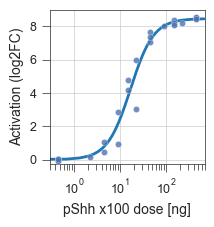

In [22]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(2,2), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})
g = sns.lineplot(data=fits[fits.model=="hill"], x="x_pred_points", y="y_pred_points", hue="model", palette="tab10", 
                linewidth=2, legend=False)
sns.scatterplot(fits[fits.model=="actual"],  x="x_pred_points", y="y_pred_points", ax=g, legend=False, 
                s=20, linewidth=0.25, zorder=10, alpha=0.8)
g.set(xscale="log", xlim=[0.3,700], ylim=[-0.25,9])
g.grid(True, linewidth=0.5)
g.set_ylabel('Activation (log2FC)', fontsize=10)
g.set_xlabel('pShh x100 dose [ng]', fontsize=10)
g.tick_params(labelsize=9)

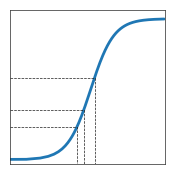

In [23]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(2,2), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})
g = sns.lineplot(data=fits[fits.model=="hill"], x="x_pred_points", y="y_pred_points", hue="model", palette="tab10", 
                linewidth=2, legend=False)
g.set(xscale="log", xlim=[0.3,700], ylim=[-0.25,9], xlabel="", ylabel="")

ypoints = [2, 3]
xpoints = [inverse_hill(y, *results["hill"]["params"]) for y in ypoints]
xpoints = xpoints + [xpoints[0]+xpoints[1]]
ypoints = ypoints + [hill(xpoints[2], *results["hill"]["params"])]
plt.tick_params(axis='y', left=False, labelleft=False)
plt.tick_params(axis='x', which="both", bottom=False, labelbottom=False)
for x, y in zip(ypoints, xpoints):
    plt.plot([-5, y, y], [x, x, -5], linewidth=0.5, color="k", linestyle="--")

In [24]:
def groupby_to_matrix(df, col1, col2, values):
    data = df.groupby([col1, col2]).mean(numeric_only=True).reset_index()
    mat = data.pivot(index=col1, columns=col2, values=values)
    return mat.combine_first(mat.T)

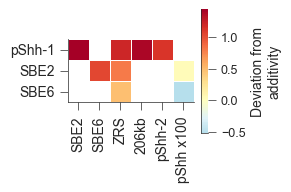

In [25]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(3,3), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})

#Calculate deviation from additive for each guide combo
df_wide = pred_all.pivot(
    index=["rep", "treatment", "combo", "actual_log2"],
    columns="function",
    values="predicted_log2"
).reset_index()
df_wide[["guide1", "guide2"]] = df_wide["combo"].str.split("+", expand=True)
df_wide["Deviation"] = df_wide["actual_log2"] - df_wide["Additive"]

#Make matrix for plotting and order
mat = groupby_to_matrix(df_wide[(df_wide["treatment"].isin(["UNT"]))], col1="guide1", col2="guide2", values="Deviation")
order =  ["pShh-1", "SBE2", "SBE6", "ZRS", "206kb", "pShh-2", "pShh x100"]
mat = mat[order]
mat = mat.T[order]

#Remove/mask duplicate values
matplot = mat.iloc[0:3].T.iloc[1:].T
mask=np.zeros_like(matplot)
mask[2,0]=1

g = sns.heatmap(
    matplot,
    mask=mask,
    cmap="RdYlBu_r",
    center=0, 
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Deviation from\nadditivity",
              "shrink": 0.5}
)

cbar = g.collections[0].colorbar
cbar.ax.tick_params(labelsize=9)

g.figure.axes[-1].yaxis.label.set_size(10)
g.set(ylabel="", xlabel="")

plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
sns.despine(bottom=False)
g.tick_params(labelsize=10)

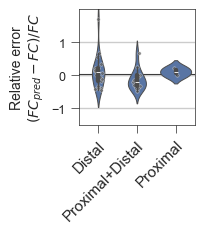

In [26]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1.5,1.5), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})
#All unperturbed conditions
df = pred_all[pred_all["treatment"].isin(["UNT"])].replace("Hill", "Response")
df["ID"] = np.where(df["combo"] == "pShh-1+pShh-2", "Proximal", 
                     np.where(df["combo"].str[:2]=="pS", "Proximal+Distal", "Distal"))
order = ["Response"]
df = df[df["function"].isin(order)]
g = sns.violinplot(data=df,
                y="rel_error", x="ID", width=0.8, linewidth=0.7, 
                )
sns.stripplot(data=df, x="ID", y="rel_error", jitter=0.1, color="dimgrey",
               linewidth=0.25, edgecolor="white", s=2.5, alpha=0.75, ax=g, zorder=1,
               )
g.set(yscale="linear", xlabel="", title="", ylim=[-1.5,2])
g.grid(True, axis="y")
plt.yticks([-1,0,1])
plt.xticks(rotation=45, ha="right", rotation_mode='anchor')
g.set_ylabel(r'Relative error' + '\n' + r'$(FC_{pred}-FC)/FC$', fontsize=10)
g.tick_params(labelsize=9, axis="y")
plt.axhline(0, zorder=-1, color="k")

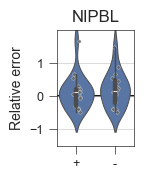

In [27]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1,1.5), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})

pred_nipbl = pred_hill[pred_hill["treatment"].isin(["DMSO_dTAG-NIPBL", "dTAG_dTAG-NIPBL"])]
order = ["DMSO_dTAG-NIPBL", "dTAG_dTAG-NIPBL"]
g = sns.violinplot(data=pred_nipbl, y="rel_error", x="treatment", width=0.9, linewidth=0.7, order=order)
sns.stripplot(data=pred_nipbl, y="rel_error", x="treatment", ax=g, linewidth=0.25, edgecolor="white", color="dimgrey", 
              s=2.5, zorder=1, alpha=0.8, order=order)
g.set(title="NIPBL", xlabel="", ylim=[-1.5,2])
plt.xticks(ticks=[0,1], labels=["+", "-"])
g.grid(True, axis="y", linewidth=0.5)
plt.yticks([-1,0,1])
plt.axhline(0, color="k",zorder=0)
g.set_ylabel("Relative error", fontsize=10)
g.tick_params(labelsize=9)

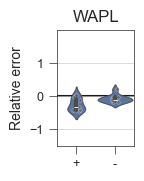

In [28]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1,1.5), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})
pred_wapl = pred_hill[pred_hill["treatment"].isin(["DMSO_WAPL-dTAG", "dTAG_WAPL-dTAG"])]
order = ["DMSO_WAPL-dTAG", "dTAG_WAPL-dTAG"]
g = sns.violinplot(data=pred_wapl, y="rel_error", x="treatment", width=0.9, linewidth=0.7, order=order)
sns.stripplot(data=pred_wapl, y="rel_error", x="treatment", ax=g, linewidth=0.25, edgecolor="white", 
              color="dimgrey", s=2.5, zorder=1, alpha=0.8, order=order)
g.set(xlabel="", title="WAPL", ylim=[-1.5,2])
plt.xticks(ticks=[0,1], labels=["+", "-"])
g.grid(True, axis="y", linewidth=0.5)
plt.yticks([-1,0,1])
plt.axhline(0, color="k",zorder=0)
g.set_ylabel("Relative error", fontsize=10)
g.tick_params(labelsize=9)

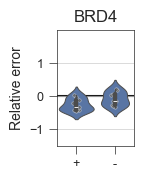

In [29]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1,1.5), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})
pred_mz1 = pred_hill[pred_hill["treatment"].isin(["DMSO_WAPL-dTAG", "MZ1_WAPL-dTAG"])]
order = ["DMSO_WAPL-dTAG", "MZ1_WAPL-dTAG"]
g = sns.violinplot(data=pred_mz1, y="rel_error", x="treatment", width=0.9, linewidth=0.7, order=order)
sns.stripplot(data=pred_mz1, y="rel_error", x="treatment", ax=g, linewidth=0.25, 
              edgecolor="white", color="dimgrey", s=2.5, zorder=1, alpha=0.8, order=order)
g.set(xlabel="", title="BRD4", ylim=[-1.5,2])
plt.xticks(ticks=[0,1], labels=["+", "-"])
g.grid(True, axis="y", linewidth=0.5)
plt.axhline(0, color="k",zorder=0)
plt.yticks([-1,0,1])
g.set_ylabel("Relative error", fontsize=10)
g.tick_params(labelsize=9)

In [30]:
pred_all.to_csv("Predictions.txt", sep="\t", index=False)